In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

DATA_PATH = '../data/cleaned_dataset.csv' if os.path.exists('../data/cleaned_dataset.csv') else 'data/cleaned_dataset.csv'
df = pd.read_csv(DATA_PATH)
df.head()

,order_id,customer_id,store_id,order_timestamp,delivery_timestamp,order_value
0,sdv-id-PPcBpb,C018496,DS007,2026-05-29 11:30:12,2026-05-29 11:40:14,204.0
1,sdv-id-NdEuVy,C006527,DS015,2026-07-15 00:01:52,2026-07-15 00:06:52,710.0
2,sdv-id-kPbvnT,C008719,DS007,2026-07-23 10:39:54,2026-07-23 10:49:54,251.0
3,sdv-id-JrFXLd,C013876,DS002,2026-06-02 02:06:09,2026-06-02 02:12:09,529.0
4,sdv-id-rNMsjf,C011488,DS005,2026-07-03 07:43:44,2026-07-03 07:49:44,515.0


Required feature engineering

In [25]:
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'])
df['delivery_timestamp'] = pd.to_datetime(df['delivery_timestamp'])
df['delivery_time_minutes']= (pd.to_datetime(df['delivery_timestamp']) - pd.to_datetime(df['order_timestamp'])).dt.total_seconds() / 60
df['hour_of_day']=df['order_timestamp'].dt.hour
df['weekday_number']=df['order_timestamp'].dt.day_name().map({'Monday': 1, 'Tuesday': 2, 'Wednesday': 3, 'Thursday': 4, 'Friday': 5, 'Saturday': 6, 'Sunday': 7})
df['day_of_week']=df['order_timestamp'].dt.day_name()
df['date']=df['order_timestamp'].dt.date
df['is_weekend'] = df['order_timestamp'].dt.dayofweek.isin([5, 6]).astype(int)

1. Distribution Analysis

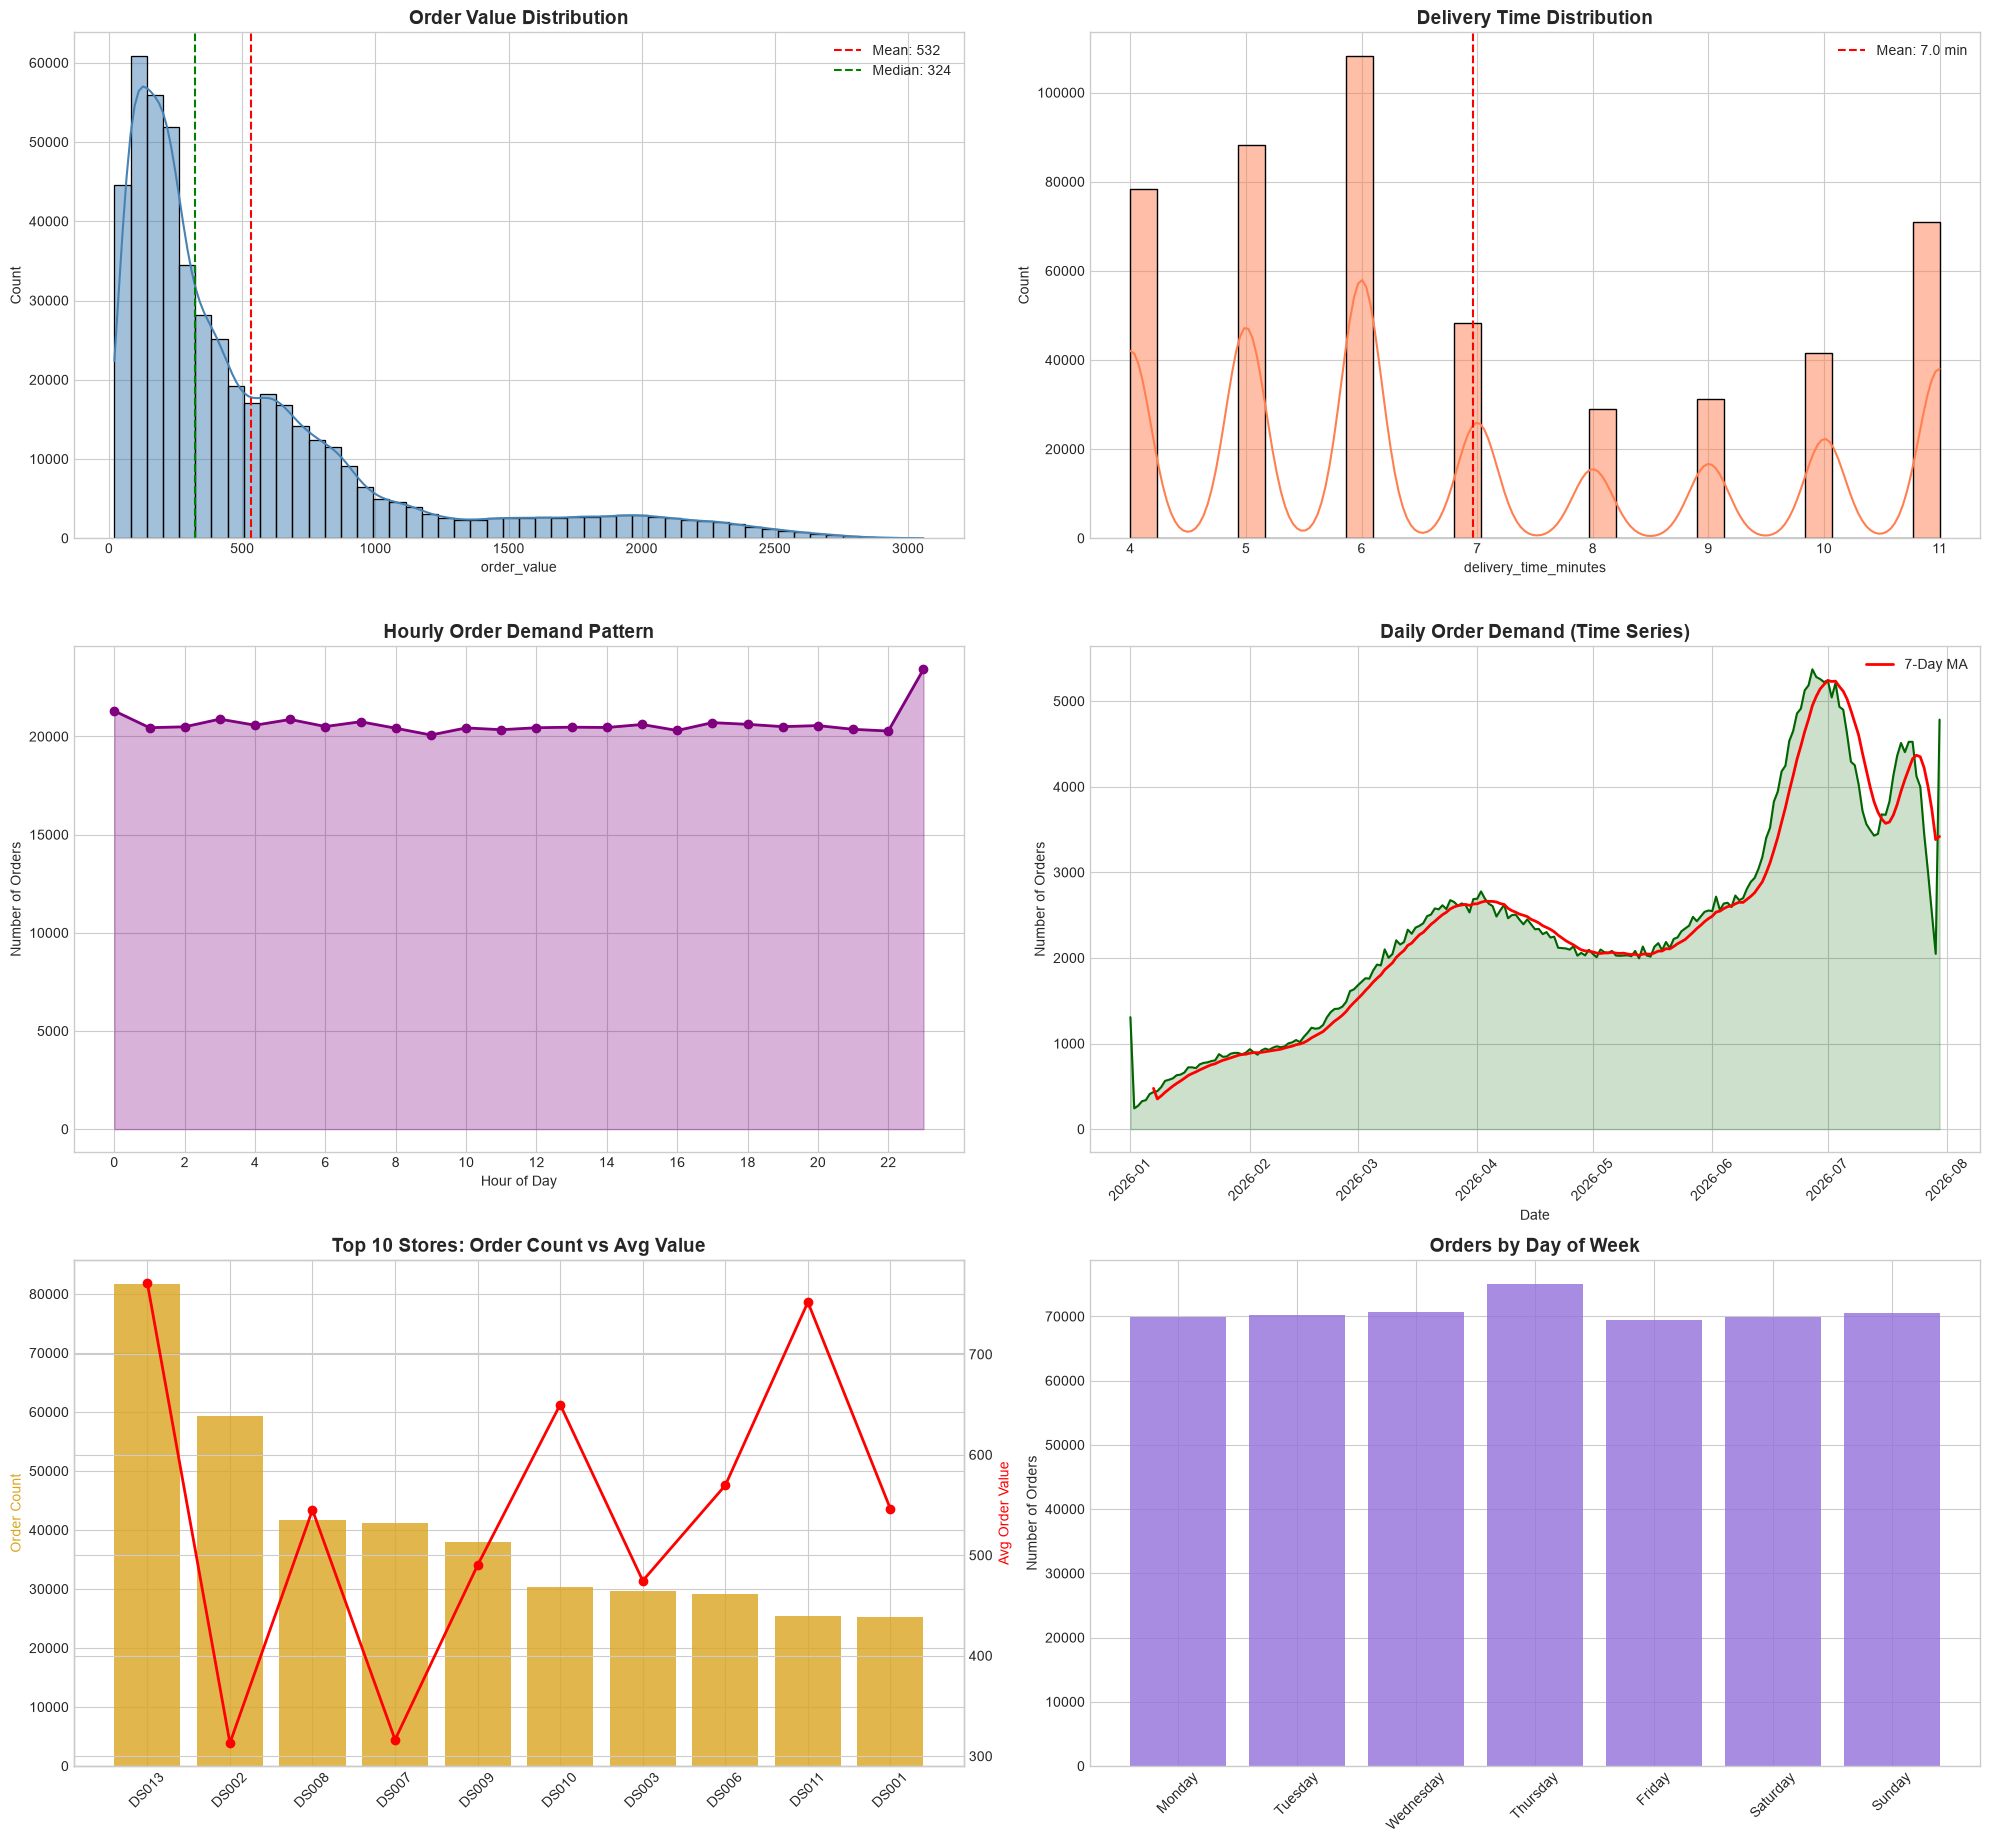

In [26]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

fig = plt.figure(figsize=(20, 24))

# Order Value Distribution
ax1 = plt.subplot(4, 2, 1)
sns.histplot(df['order_value'], bins=50, kde=True, ax=ax1, color='steelblue')
ax1.axvline(df['order_value'].mean(), color='red', linestyle='--', label=f'Mean: {df["order_value"].mean():.0f}')
ax1.axvline(df['order_value'].median(), color='green', linestyle='--', label=f'Median: {df["order_value"].median():.0f}')
ax1.set_title('Order Value Distribution', fontsize=14, fontweight='bold')
ax1.legend()

# Delivery Time Distribution
ax2 = plt.subplot(4, 2, 2)
sns.histplot(df['delivery_time_minutes'], bins=30, kde=True, ax=ax2, color='coral')
ax2.axvline(df['delivery_time_minutes'].mean(), color='red', linestyle='--', label=f'Mean: {df["delivery_time_minutes"].mean():.1f} min')
ax2.set_title('Delivery Time Distribution', fontsize=14, fontweight='bold')
ax2.legend()

# Hourly Demand Pattern
ax3 = plt.subplot(4, 2, 3)
hourly_orders = df.groupby('hour_of_day').size()
ax3.plot(hourly_orders.index, hourly_orders.values, marker='o', linewidth=2, markersize=6, color='purple')
ax3.fill_between(hourly_orders.index, hourly_orders.values, alpha=0.3, color='purple')
ax3.set_title('Hourly Order Demand Pattern', fontsize=14, fontweight='bold')
ax3.set_xlabel('Hour of Day')
ax3.set_ylabel('Number of Orders')
ax3.set_xticks(range(0, 24, 2))

# Daily Demand Time Series
ax6 = plt.subplot(4, 2, 4)
daily_orders = df.groupby('date').size()
ax6.plot(daily_orders.index, daily_orders.values, color='darkgreen', linewidth=1.5)
ax6.fill_between(daily_orders.index, daily_orders.values, alpha=0.2, color='darkgreen')

# Add 7-day rolling average
daily_orders_rolling = daily_orders.rolling(window=7).mean()
ax6.plot(daily_orders_rolling.index, daily_orders_rolling.values, color='red', linewidth=2, label='7-Day MA')
ax6.set_title('Daily Order Demand (Time Series)', fontsize=14, fontweight='bold')
ax6.set_xlabel('Date')
ax6.set_ylabel('Number of Orders')
ax6.legend()
ax6.tick_params(axis='x', rotation=45)

# Store Performance
ax7 = plt.subplot(4, 2, 5)
store_perf = df.groupby('store_id').agg({'order_value': 'mean', 'order_id': 'count'}).rename(columns={'order_id': 'order_count'})
store_perf = store_perf.sort_values('order_count', ascending=False).head(10)
x_pos = range(len(store_perf))
ax7.bar(x_pos, store_perf['order_count'], color='goldenrod', alpha=0.8, label='Order Count')
ax7_twin = ax7.twinx()
ax7_twin.plot(x_pos, store_perf['order_value'], color='red', marker='o', linewidth=2, label='Avg Order Value')
ax7.set_xticks(x_pos)
ax7.set_xticklabels(store_perf.index, rotation=45)
ax7.set_title('Top 10 Stores: Order Count vs Avg Value', fontsize=14, fontweight='bold')
ax7.set_ylabel('Order Count', color='goldenrod')
ax7_twin.set_ylabel('Avg Order Value', color='red')

# Day of Week Pattern
ax8 = plt.subplot(4, 2, 6)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_orders = df['day_of_week'].value_counts().reindex(day_order).fillna(0)
ax8.bar(dow_orders.index, dow_orders.values, color='mediumpurple', alpha=0.8)
ax8.set_title('Orders by Day of Week', fontsize=14, fontweight='bold')
ax8.set_ylabel('Number of Orders')
ax8.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

2. Relationship & Correlation Analysis

<Axes: >

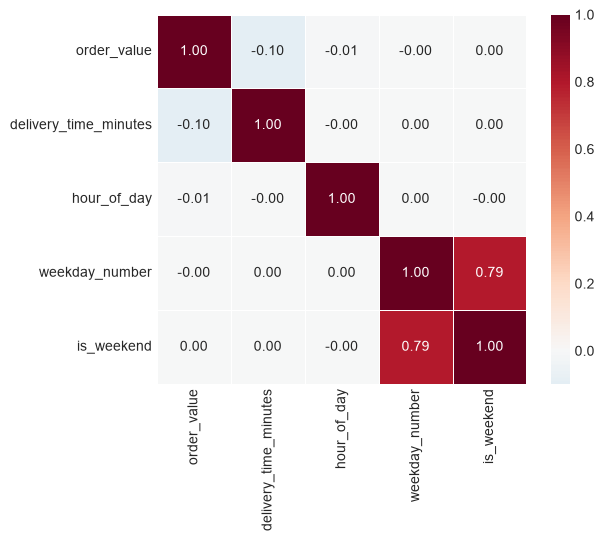

In [27]:
# Correlation matrix and heatmap
corr_cols = [
    'order_value',
    'delivery_time_minutes',
    'hour_of_day',
    'weekday_number',
    'is_weekend',
]

corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, linewidths=0.5)

In [28]:
# Customer satisfaction
SLA_MIN = 10 

df["customer_satisfaction"] = np.where(df["delivery_time_minutes"] <= SLA_MIN,"Satisfied","Not Satisfied")

# numeric score of satisfaction
df["satisfaction_score"] = np.clip(1 - (df["delivery_time_minutes"] / SLA_MIN),0, 1)

In [29]:
df.head(10)

,order_id,customer_id,store_id,order_timestamp,delivery_timestamp,order_value,delivery_time_minutes,hour_of_day,weekday_number,day_of_week,date,is_weekend,customer_satisfaction,satisfaction_score
0,sdv-id-PPcBpb,C018496,DS007,2026-05-29 11:30:12,2026-05-29 11:40:14,204.0,10.033333,11,5,Friday,2026-05-29,0,Not Satisfied,0.0
1,sdv-id-NdEuVy,C006527,DS015,2026-07-15 00:01:52,2026-07-15 00:06:52,710.0,5.000000,0,3,Wednesday,2026-07-15,0,Satisfied,0.5
2,sdv-id-kPbvnT,C008719,DS007,2026-07-23 10:39:54,2026-07-23 10:49:54,251.0,10.000000,10,4,Thursday,2026-07-23,0,Satisfied,0.0
3,sdv-id-JrFXLd,C013876,DS002,2026-06-02 02:06:09,2026-06-02 02:12:09,529.0,6.000000,2,2,Tuesday,2026-06-02,0,Satisfied,0.4
4,sdv-id-rNMsjf,C011488,DS005,2026-07-03 07:43:44,2026-07-03 07:49:44,515.0,6.000000,7,5,Friday,2026-07-03,0,Satisfied,0.4
5,sdv-id-YdxfnV,C006400,DS013,2026-02-03 07:14:02,2026-02-03 07:18:02,768.0,4.000000,7,2,Tuesday,2026-02-03,0,Satisfied,0.6
6,sdv-id-WZqOBZ,C012274,DS011,2026-01-30 06:31:39,2026-01-30 06:37:39,2442.0,6.000000,6,5,Friday,2026-01-30,0,Satisfied,0.4
7,sdv-id-MxmlhI,C002128,DS009,2026-05-22 08:09:36,2026-05-22 08:15:36,883.0,6.000000,8,5,Friday,2026-05-22,0,Satisfied,0.4
8,sdv-id-sBgmlK,C004954,DS014,2026-07-16 14:45:19,2026-07-16 14:51:19,680.0,6.000000,14,4,Thursday,2026-07-16,0,Satisfied,0.4
9,sdv-id-DhETWS,C006702,DS010,2026-05-18 15:21:33,2026-05-18 15:27:33,1286.0,6.000000,15,1,Monday,2026-05-18,0,Satisfied,0.4


In [30]:
counts=df['customer_satisfaction'].value_counts()
print(counts)

customer_satisfaction
Satisfied        406260
Not Satisfied     89614
Name: count, dtype: int64


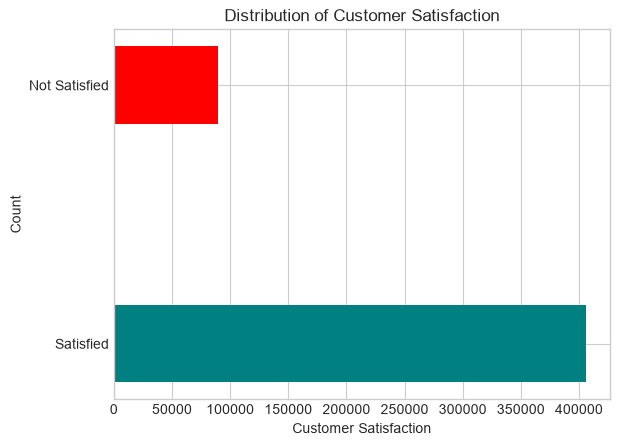

In [31]:

plt.barh(counts.index, counts.values, color=['teal', 'red'] , height=0.3)
plt.ylabel('Count')
plt.xlabel('Customer Satisfaction')
plt.title('Distribution of Customer Satisfaction')
plt.show()

In [32]:
# correlation between delivery time and satisfaction score
from scipy.stats import pearsonr
r,p= pearsonr(df['delivery_time_minutes'], df['satisfaction_score'])
print(f"Pearson correlation coefficient: {r:.2f}, p-value: {p:.4f}")

Pearson correlation coefficient: -0.99, p-value: 0.0000


c:\Users\Syandip\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


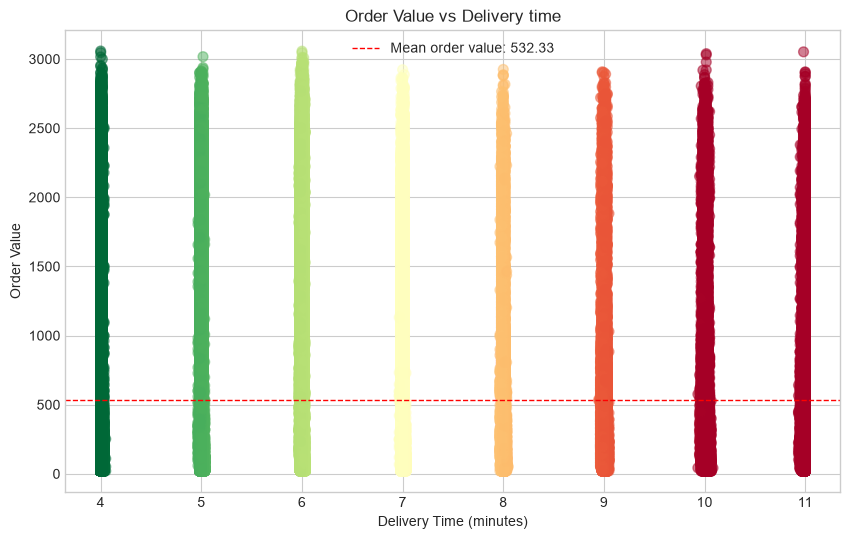

In [33]:
# Scatter Plot : Order value vs delivery time
mean_order_value = df["order_value"].mean()

plt.figure(figsize=(10, 6))
plt.scatter(
    df["delivery_time_minutes"],
    df["order_value"],
    c=df["satisfaction_score"],
    cmap="RdYlGn",
    alpha=0.5,
    s=50
)
plt.axhline(
    mean_order_value,
    color='red',
    linestyle='--',
    linewidth=1,
    label=f'Mean order value: {mean_order_value:.2f}'
)
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Order Value")
plt.title("Order Value vs Delivery time")
plt.legend()
plt.show()

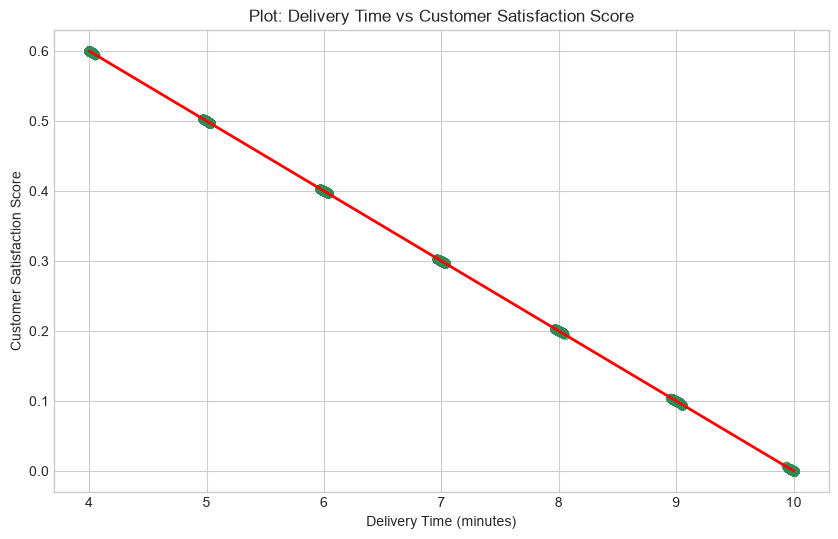

In [34]:
# Scatter : delivery Time vs Customer Satisfaction Score
plt.figure(figsize=(10, 6))
filter_df=df[df['delivery_time_minutes']<=10]
plt.scatter(filter_df['delivery_time_minutes'], filter_df['satisfaction_score'], color='seagreen', alpha=0.5)
sns.regplot(x=filter_df['delivery_time_minutes'], y=filter_df['satisfaction_score'], data=df, scatter=False, color='red', line_kws={'linewidth':2})
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Customer Satisfaction Score')
plt.title('Plot: Delivery Time vs Customer Satisfaction Score')
plt.show()

C:\Users\Syandip\AppData\Local\Temp\ipykernel_13748\2237504640.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend()
C:\Users\Syandip\AppData\Local\Temp\ipykernel_13748\2237504640.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()
C:\Users\Syandip\AppData\Local\Temp\ipykernel_13748\2237504640.py:61: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax4.legend()


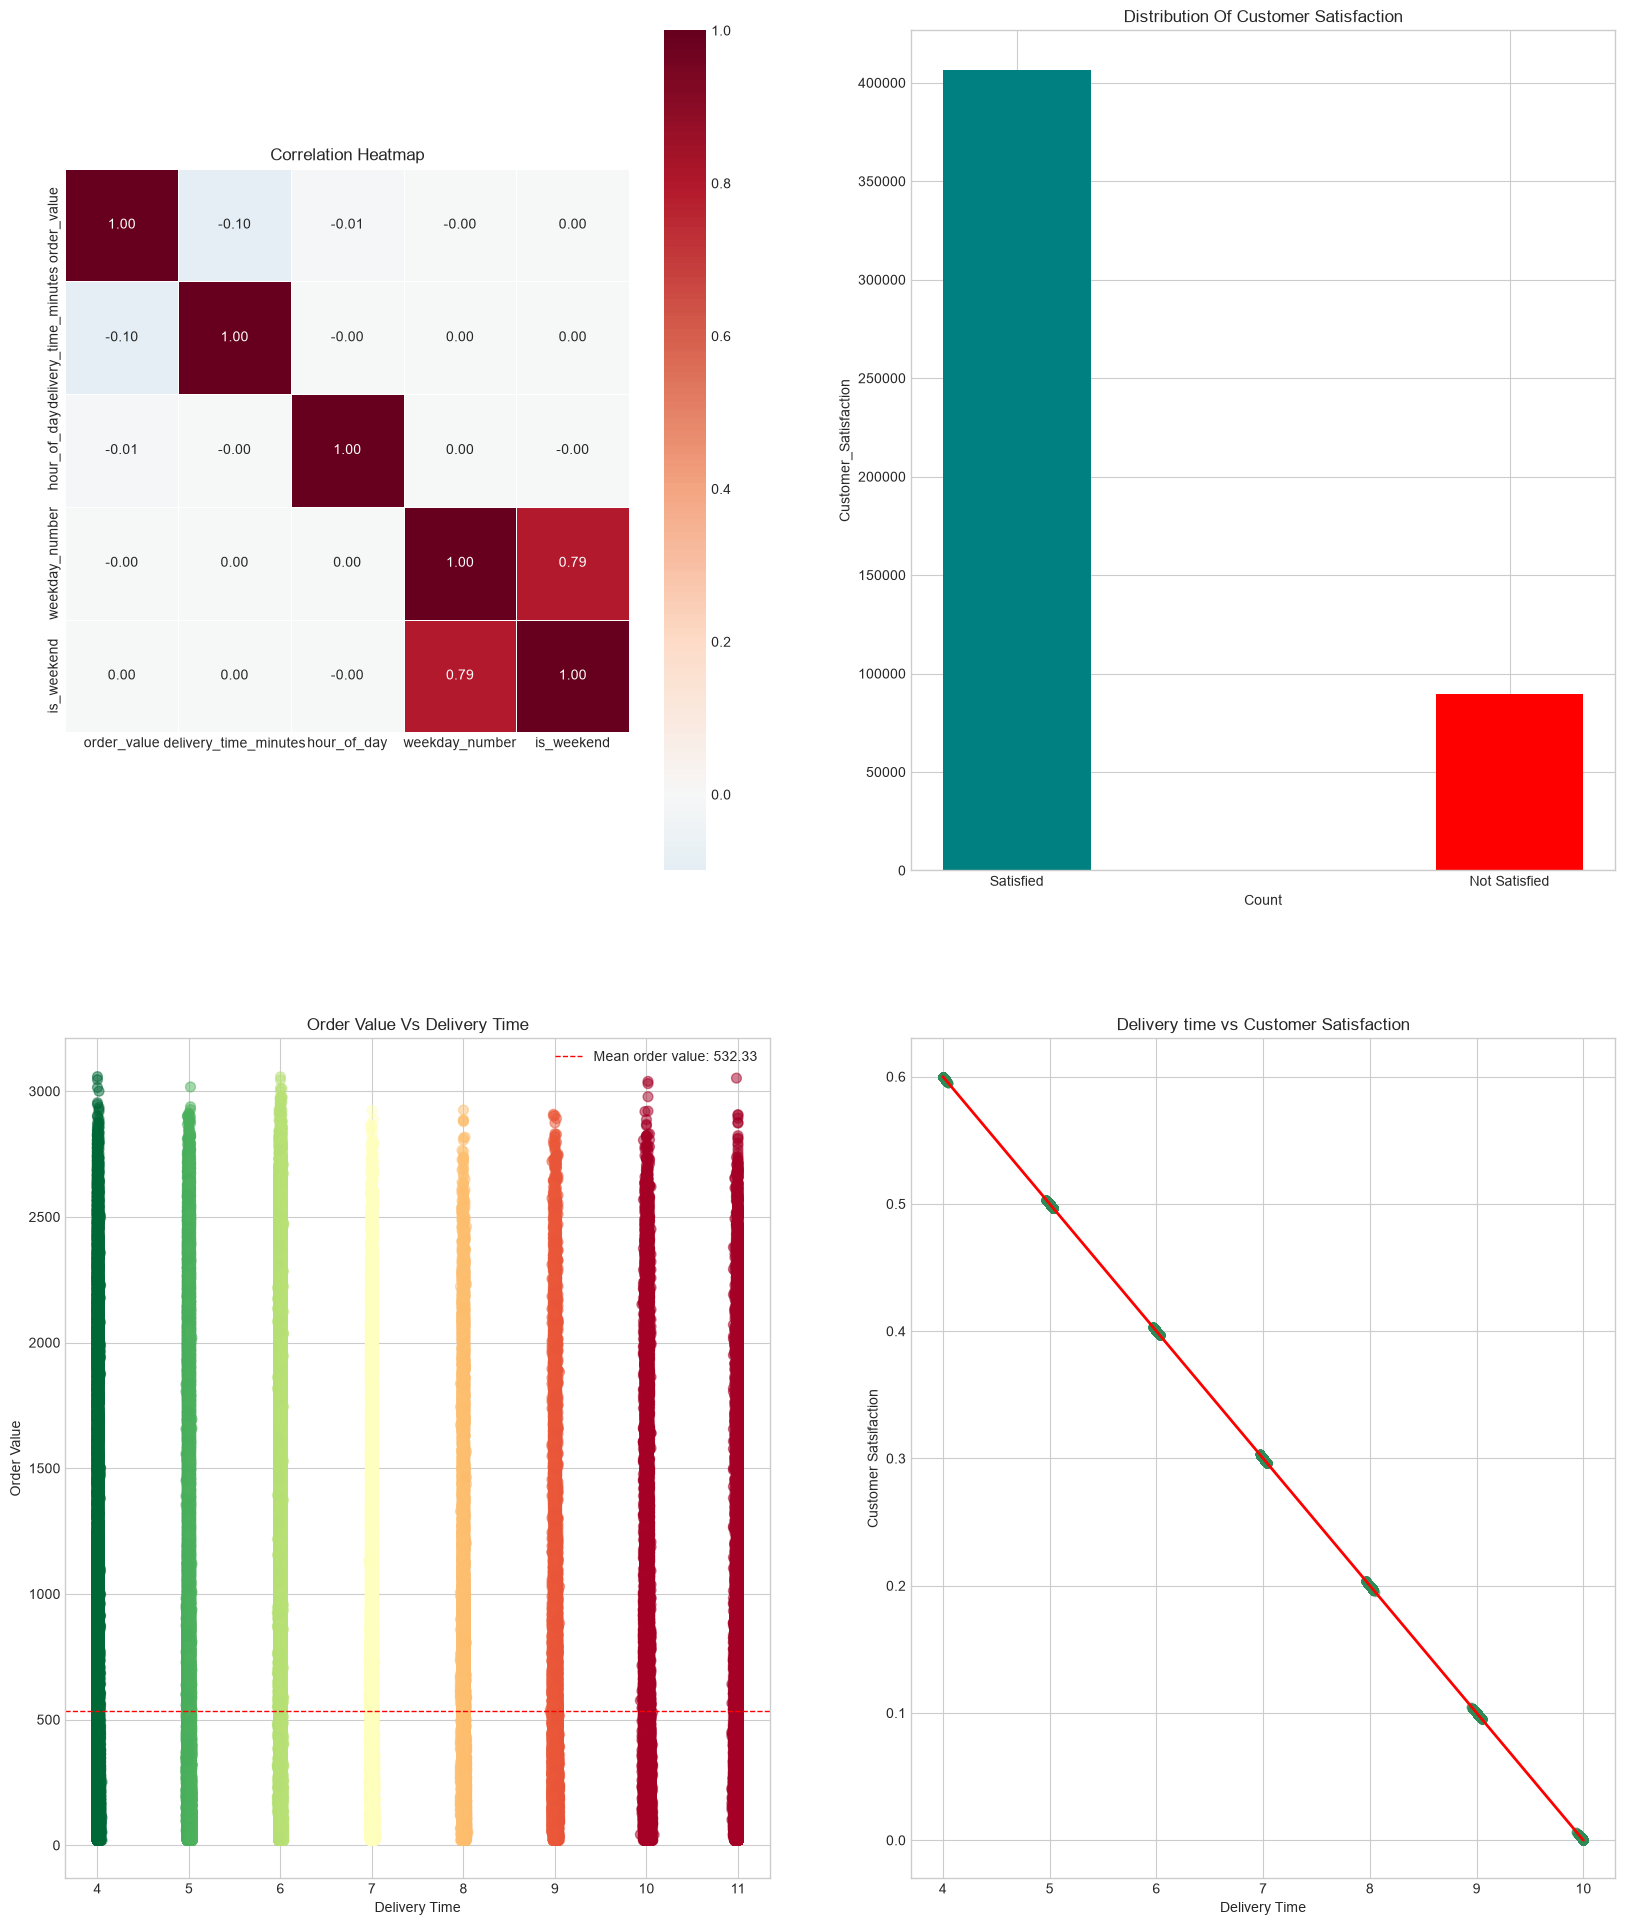

In [35]:
# Correlation Analysis (Tight layout)
fig = plt.figure(figsize=(20, 24))

# Correlational heatmap
ax1=plt.subplot(2,2,1)
corr_cols = ['order_value','delivery_time_minutes','hour_of_day','weekday_number','is_weekend']
corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, linewidths=0.5)
ax1.set_title("Correlation Heatmap")
ax1.legend()

# Customer satisfaction
SLA_MIN = 10 

df["customer_satisfaction"] = np.where(df["delivery_time_minutes"] <= SLA_MIN,"Satisfied","Not Satisfied")

# numeric score of satisfaction
df["satisfaction_score"] = np.clip(1 - (df["delivery_time_minutes"] / SLA_MIN),0, 1)

# Distribution Of Customer Satisfaction

ax2=plt.subplot(2,2,2)
plt.bar(counts.index, counts.values, color=['teal', 'red'] , width=0.3)
ax2.set_title("Distribution Of Customer Satisfaction")
ax2.set_xlabel("Count")
ax2.set_ylabel("Customer_Satisfaction")
ax2.legend()

# Scatter Plot: Order value Vs Delivery Time (Colored by Customer Satisfaction)

ax3=plt.subplot(2,2,3)
mean_order_value = df["order_value"].mean()
plt.scatter(
    df["delivery_time_minutes"],
    df["order_value"],
    c=df["satisfaction_score"],
    cmap="RdYlGn",
    alpha=0.5,
    s=50
)
plt.axhline(
    mean_order_value,
    color='red',
    linestyle='--',
    linewidth=1,
    label=f'Mean order value: {mean_order_value:.2f}'
)
ax3.set_xlabel('Delivery Time')
ax3.set_ylabel('Order Value')
ax3.set_title('Order Value Vs Delivery Time')
ax3.legend()

# Plot: Customer Satisfaction vs Delivery Time
ax4=plt.subplot(2,2,4)
filter_df=df[df['delivery_time_minutes']<=10]
plt.scatter(filter_df['delivery_time_minutes'], filter_df['satisfaction_score'], color='seagreen', alpha=0.5)
sns.regplot(x=filter_df['delivery_time_minutes'], y=filter_df['satisfaction_score'], data=df, scatter=False, color='red', line_kws={'linewidth':2})
ax4.set_xlabel('Delivery Time')
ax4.set_ylabel('Customer Satsifaction')
ax4.set_title('Delivery time vs Customer Satisfaction')
ax4.legend()

3. Temporal Seasonality Analysis

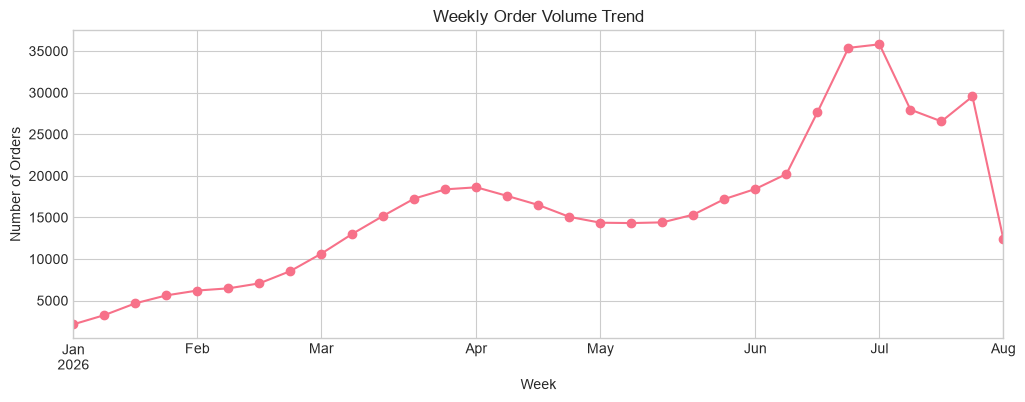

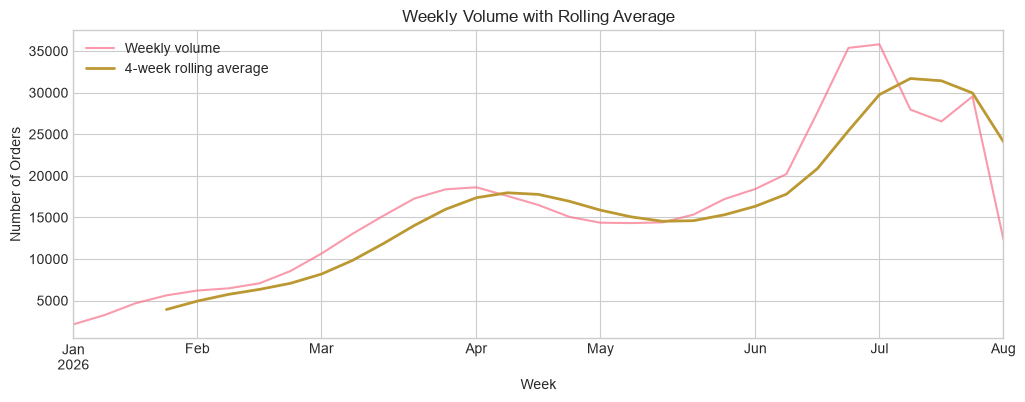

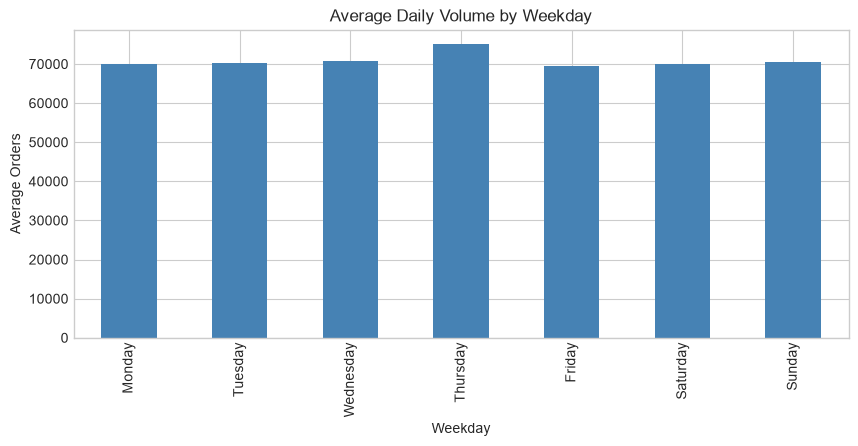

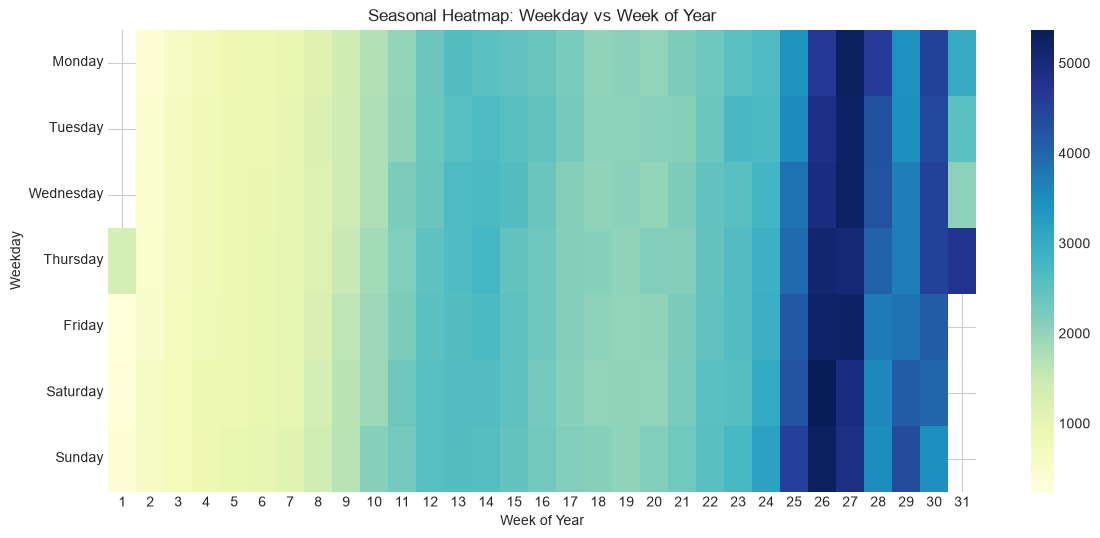

In [36]:
# 1. Weekly trends
weekly_trends = df.resample('W', on='order_timestamp').size()
weekly_trends.plot(figsize=(12, 4), marker='o')
plt.title('Weekly Order Volume Trend')
plt.xlabel('Week')
plt.ylabel('Number of Orders')
plt.show()

# 2. Rolling averages
rolling_avg = weekly_trends.rolling(window=4).mean()
weekly_trends.plot(figsize=(12, 4), label='Weekly volume', alpha=0.7)
rolling_avg.plot(label='4-week rolling average', linewidth=2)
plt.title('Weekly Volume with Rolling Average')
plt.xlabel('Week')
plt.ylabel('Number of Orders')
plt.legend()
plt.show()

# 3. Average volume by weekday
weekday_profile = df.groupby('day_of_week').size().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])
weekday_profile.plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Average Daily Volume by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Orders')
plt.show()

# 4. Seasonal heatmap: weekday vs week of year
heatmap_data = df.set_index('order_timestamp').resample('D').size().to_frame('orders')
heatmap_data['weekday'] = heatmap_data.index.day_name()
heatmap_data['week_of_year'] = heatmap_data.index.isocalendar().week
pivot = heatmap_data.pivot_table(index='weekday', columns='week_of_year', values='orders', aggfunc='mean')
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot = pivot.reindex(index=weekday_order)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot, cmap='YlGnBu', annot=False)
plt.title('Seasonal Heatmap: Weekday vs Week of Year')
plt.xlabel('Week of Year')
plt.ylabel('Weekday')
plt.show()

4. Spatial / Location Analysis

          order_volume  total_revenue
store_id                             
DS013            81649     62932236.0
DS002            59361     18584202.0
DS008            41778     22772759.0
DS007            41230     13044662.0
DS009            37915     18582747.0
DS010            30328     19710083.0
DS003            29612     14053751.0
DS006            29224     16645065.0
DS011            25429     19118564.0
DS001            25193     13756067.0


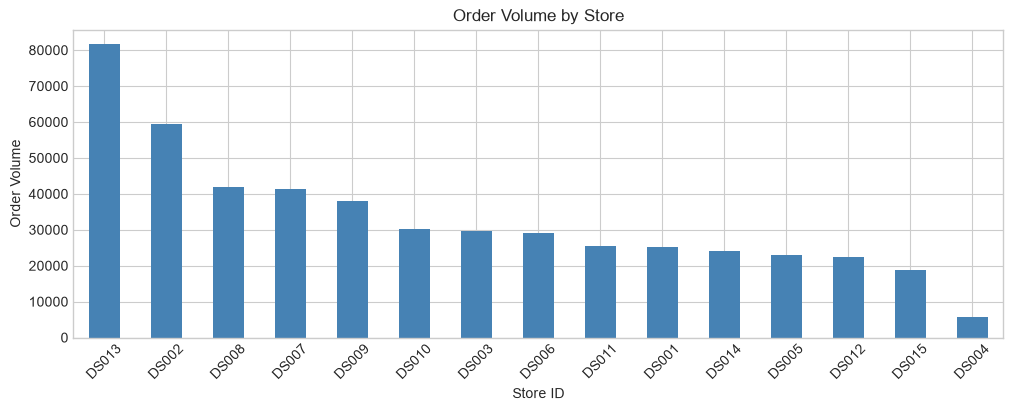

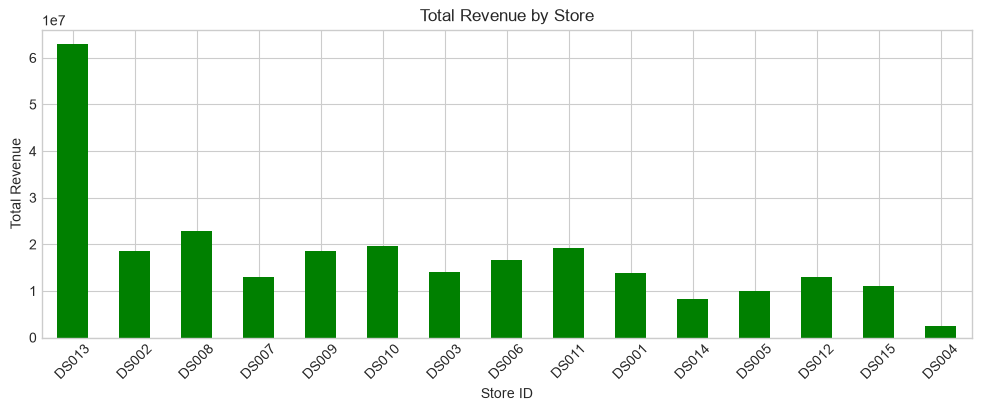

In [37]:
# Store contribution analysis
store_summary = (
    df.groupby('store_id')
      .agg(
          order_volume=('order_id', 'count'),
          total_revenue=('order_value', 'sum')
      )
      .sort_values('order_volume', ascending=False)
)

# Show top stores
print(store_summary.head(10))

# Bar chart: order volume by store
store_summary['order_volume'].plot(kind='bar', figsize=(12, 4), color='steelblue')
plt.title('Order Volume by Store')
plt.xlabel('Store ID')
plt.ylabel('Order Volume')
plt.xticks(rotation=45)
plt.show()

# Bar chart: total revenue by store
store_summary['total_revenue'].plot(kind='bar', figsize=(12, 4), color='green')
plt.title('Total Revenue by Store')
plt.xlabel('Store ID')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

In [38]:
OUT_PATH = '../data/eda_output.csv' if os.path.exists('../data') else 'data/eda_output.csv'
df.to_csv(OUT_PATH, index=False)

5. Final Insights 

In [39]:
# 1) Basic dataset size
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

# 2) Order value summary
print('\nOrder Value Summary:')
print(df['order_value'].describe())

# 3) Delivery time summary
print('\nDelivery Time Summary:')
print(df['delivery_time_minutes'].describe())

# 4) Satisfaction split
print('\nCustomer Satisfaction Split:')
print(df['customer_satisfaction'].value_counts())

# 5) Correlation summary
corr_cols = ['order_value', 'delivery_time_minutes', 'hour_of_day', 'weekday_number', 'is_weekend']
corr_summary = df[corr_cols].corr()['order_value'].sort_values(ascending=False)
print('\nCorrelation with Order Value:')
print(corr_summary)

# 6) Store contribution summary
store_summary = (
    df.groupby('store_id')
      .agg(
          order_volume=('order_id', 'count'),
          total_revenue=('order_value', 'sum'),
          avg_delivery_time=('delivery_time_minutes', 'mean')
      )
      .sort_values('order_volume', ascending=False)
)
print('\nStore Contribution Summary:')
print(store_summary.head())


# 7) Weekday demand summary
weekday_summary = df.groupby('day_of_week').size().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])
print('\nOrders by Day of Week:')
print(weekday_summary)

# 8) Hourly demand summary
hourly_summary = df.groupby('hour_of_day').size()
print('\nOrders by Hour of Day:')
print(hourly_summary.head(10))

# 9) HoH growth-rate summary
hourly_volume = df.set_index('order_timestamp').resample('H').size()
hoh_growth = hourly_volume.pct_change() * 100
print('\nTop HoH Growth Spikes:')
print(hoh_growth.dropna().sort_values(ascending=False).head(10))

Rows: 495874
Columns: 14

Order Value Summary:
count    495874.000000
mean        532.334079
std         553.875889
min          20.000000
25%         162.000000
50%         324.000000
75%         688.000000
max        3058.000000
Name: order_value, dtype: float64

Delivery Time Summary:
count    495874.000000
mean          6.960753
std           2.388261
min           4.000000
25%           5.000000
50%           6.000000
75%           9.000000
max          11.000000
Name: delivery_time_minutes, dtype: float64

Customer Satisfaction Split:
customer_satisfaction
Satisfied        406260
Not Satisfied     89614
Name: count, dtype: int64

Correlation with Order Value:
order_value              1.000000
is_weekend               0.001046
weekday_number          -0.000429
hour_of_day             -0.008087
delivery_time_minutes   -0.099377
Name: order_value, dtype: float64

Store Contribution Summary:
          order_volume  total_revenue  avg_delivery_time
store_id                            

C:\Users\Syandip\AppData\Local\Temp\ipykernel_13748\3756366678.py:50: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly_volume = df.set_index('order_timestamp').resample('H').size()



Top HoH Growth Spikes:
order_timestamp
2026-07-30 23:00:00    5812.727273
2026-01-09 22:00:00     271.428571
2026-01-03 03:00:00     200.000000
2026-01-02 07:00:00     200.000000
2026-01-01 08:00:00     200.000000
2026-01-03 08:00:00     133.333333
2026-01-03 16:00:00     128.571429
2026-01-05 22:00:00     118.181818
2026-01-05 18:00:00     111.111111
2026-01-14 05:00:00     106.666667
dtype: float64
